# Bayesian Optimization

In [37]:
import os
import joblib
import warnings
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from bayes_opt import BayesianOptimization
from sklearn.preprocessing import PolynomialFeatures
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import MinMaxScaler

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)
pd.set_option("future.no_silent_downcasting", True)
plt.style.use("dark_background")
warnings.filterwarnings("ignore")

## Import and Prepare Data

**Select either  `removal` or `recovery` as the desired Output here!**

**Select a model from this list:**

**- `model_lin_reg`**

**- `model_gbrt`**

**- `model_random_forest`**

After selecting the desired output and model, the required data is imported. For simplicity, the features (*Flow_C*, *Flow_P*, and *Current_Limit_P*) are always imported from the cache folder here, which saves having to convert them to the correct format from the CSV files. Depending on which output variable you selected previously, either the data, quadratic features and linear model for the output variable *Average Salt Removal* or *Average Water Recovery* is loaded. The scaler used in the data preparation step is always imported to inverse transform the results.

In [38]:
output = "recovery"
select_model = "model_random_forest"

In [39]:
cached_objects_data_path = os.path.join(
    os.path.dirname(os.getcwd()), "..", "cached_objects"
)

X = joblib.load(os.path.join(cached_objects_data_path, "prepared_data", "X.npy"))

if output == "removal":
    y = joblib.load(
        os.path.join(cached_objects_data_path, "prepared_data", "y_removal.npy")
    ).reshape(-1, 1)
    y_label = joblib.load(
        os.path.join(cached_objects_data_path, "prepared_data", "y_label_removal.npy")
    )
    y_name = "removal"
    poly: PolynomialFeatures = joblib.load(
        os.path.join(
            cached_objects_data_path, "model_lin_reg", "removal", "poly_features.pkl"
        )
    )
    match select_model:
        case "model_lin_reg":
            model: LinearRegression = joblib.load(
                os.path.join(
                    cached_objects_data_path,
                    "model_lin_reg",
                    "removal",
                    "linear_model.pkl",
                )
            )
        case "model_gbrt":
            model: GradientBoostingRegressor = joblib.load(
                os.path.join(
                    cached_objects_data_path,
                    "model_gbrt",
                    "removal",
                    "gbrt_model.pkl",
                )
            )
        case "model_random_forest":
            model: RandomForestRegressor = joblib.load(
                os.path.join(
                    cached_objects_data_path,
                    "model_random_forest",
                    "removal",
                    "rf_model.pkl",
                )
            )
    X_quad = joblib.load(
        os.path.join(cached_objects_data_path, "model_lin_reg", "removal", "X_quad.npy")
    )
elif output == "recovery":
    y = joblib.load(
        os.path.join(cached_objects_data_path, "prepared_data", "y_recovery.npy")
    ).reshape(-1, 1)
    y_label = joblib.load(
        os.path.join(cached_objects_data_path, "prepared_data", "y_label_recovery.npy")
    )
    y_name = "recovery"
    poly: PolynomialFeatures = joblib.load(
        os.path.join(
            cached_objects_data_path, "model_lin_reg", "recovery", "poly_features.pkl"
        )
    )
    match select_model:
        case "model_lin_reg":
            model: LinearRegression = joblib.load(
                os.path.join(
                    cached_objects_data_path,
                    "model_lin_reg",
                    "recovery",
                    "linear_model.pkl",
                )
            )
        case "model_gbrt":
            model: GradientBoostingRegressor = joblib.load(
                os.path.join(
                    cached_objects_data_path,
                    "model_gbrt",
                    "recovery",
                    "gbrt_model.pkl",
                )
            )
        case "model_random_forest":
            model: RandomForestRegressor = joblib.load(
                os.path.join(
                    cached_objects_data_path,
                    "model_random_forest",
                    "recovery",
                    "rf_model.pkl",
                )
            )
    X_quad = joblib.load(
        os.path.join(
            cached_objects_data_path, "model_lin_reg", "recovery", "X_quad.npy"
        )
    )

scaler: MinMaxScaler = joblib.load(
    os.path.join(cached_objects_data_path, "prepared_data", "scaler.pkl")
)

## Simple Constrained Bayesian Optimization

Here, another option for optimizing black-box functions is applied. With the *Bayesian Optimization*, an acquisition function decides after each iteration which point will be evaluated next in order to reduce the estimated uncertainties as much as possible.

For a very simple setup, you need:
- A *Black-Box Function* that needs to be optimized. Here the models from the previous steps come into play. These models are used to make predictions in the black-box function, which are then included in the optimization as new points. This function is structured in such a way that the underlying model can be easily replaced. For the model created by linear regression, additional constraints are also necessary, as the output must always be between 0 and 1. This is communicated to the optimizer via a penalty in the form of a negative value. A minimum implementation requires the following parts to be defined:
- Limits are set for the input variables that must not be exceeded by the optimizer.
- An optimizer itself is required too.
- It is also important to register all available data points with the optimizer.
- Finally, the actual optimization is performed and the results are transformed back to the original value range.

Extensive testing has revealed a number of sensitive adjustment parameters that need to be examined more closely:
- Calculating penalties for exceeding or falling below the permitted value range has a significant impact on the result.
- Expert knowledge can be used to narrow down the range of values for the input variables in which the optimizer searches for new values, which can lead to a more meaningful result.
- It may be worthwhile to specifically remove values from the measured values in order to obtain suggestions from the optimizer.
- Of course, the number of iterations also has an influence on the optimization result. However, since no real settling behavior can be observed anyway, it is best to start with about 100 iterations.

The graph below can be used to evaluate whether Bayesian optimization is suitable for this application. It shows how the error and the correct result behave across all iterations. A good result would be a kind of settling behavior, as this would show that the error decreases with each iteration and the result is realistic  and usable. Unfortunately, this behavior cannot be observed, at least in the quadratic model, where strong outliers still occur even after many iterations. In the GBRT and Random Forest models, the error is almost constant across all iterations with the big difference that the error for the output *Average Salt Removal* is always close to 0, while the error for the average water recovery is around 0.65.


Optimal Flow_C 0.45
Optimal Flow_P: 0.5
Optimal Current_Limit_P: 55.0
Maximum Average Water Recovery (%): 36.0


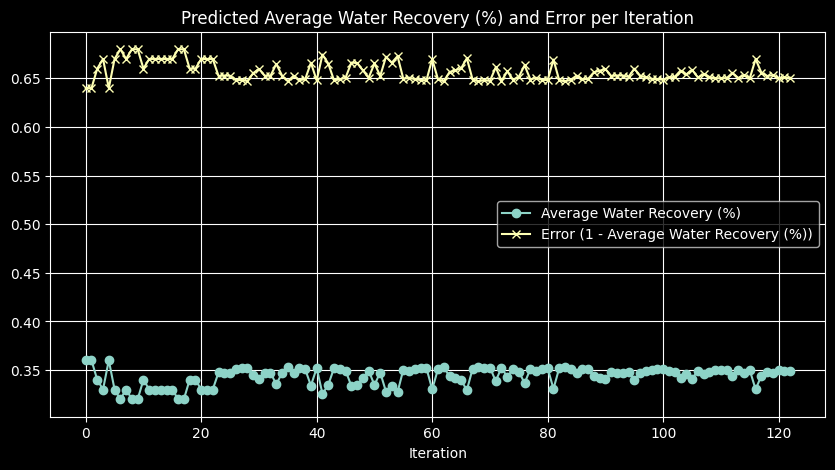

In [ ]:
# Define the black-box function to be optimized
def black_box_function(Flow_C, Flow_P, Current_Limit_P, penalty_scale=5.0):
    x = np.array([Flow_C, Flow_P, Current_Limit_P]).reshape(1, -1)
    match select_model:
        case "model_lin_reg":
            x_quad = poly.transform(x)
            y_pred = model.predict(x_quad)[0, 0]
            # Set constraints here to penalise out of range values
            if y_pred < 0:
                y_pred_penalized = y_pred - penalty_scale * abs(y_pred)
            elif y_pred > 1:
                y_pred_penalized = y_pred - penalty_scale * (y_pred - 1)
            else:
                y_pred_penalized = y_pred
            return y_pred_penalized
        case "model_gbrt":
            y_pred = model.predict(x)[0]
            return y_pred
        case "model_random_forest":
            y_pred = model.predict(x)[0]
            return y_pred


# Specify the maximum and minimum values to be probed by the optimizer
pbounds = {
    "Flow_C": (0.0, X[:, 0].max()),
    "Flow_P": (0.0, X[:, 1].max()),
    "Current_Limit_P": (0.0, X[:, 2].max()),
}

# Create the optimizer
optimizer = BayesianOptimization(
    f=black_box_function,
    pbounds=pbounds,
    verbose=0,
    random_state=42,
    allow_duplicate_points=False,
)

# Register all existing data points and exclude the dublicate ones
excluded_output_vals = [0.99]
registered_points = set()
for i in range(len(X)):
    if y[i, 0] not in excluded_output_vals:
        point = (X[i, 0], X[i, 1], X[i, 2])
        if point not in registered_points:
            optimizer.register(
                params={
                    "Flow_C": X[i, 0],
                    "Flow_P": X[i, 1],
                    "Current_Limit_P": X[i, 2],
                },
                target=y[i, 0],
            )
            registered_points.add(point)

# Perform actual maximize step
optimizer.maximize(
    init_points=0,
    n_iter=100,
)

results = pd.DataFrame(
    [
        {
            "Flow_C": r["params"]["Flow_C"],
            "Flow_P": r["params"]["Flow_P"],
            "Current_Limit_P": r["params"]["Current_Limit_P"],
            y_label: r["target"],
            "Error": 1.0 - r["target"],
        }
        for r in optimizer.res
    ]
)

# Transform results back into original value ranges
inputs = np.array(list(optimizer.max.get("params").values()))
best_x_original = scaler.inverse_transform(inputs.reshape(1, -1))[0]
best_y_origional = optimizer.max.get("target") * 100

# Print results
print("Optimal Flow_C", best_x_original[0])
print("Optimal Flow_P:", best_x_original[1])
print("Optimal Current_Limit_P:", best_x_original[2])
print(f"Maximum {y_label}:", best_y_origional)

# Plot the error against the actual output values
plt.figure(figsize=(10, 5))

plt.plot(results.index, results[y_label], marker="o", label=y_label)

plt.plot(results.index, results["Error"], marker="x", label=f"Error (1 - {y_label})")

plt.xlabel("Iteration")
plt.title(f"Predicted {y_label} and Error per Iteration")
plt.legend()
plt.grid(True)
plt.show()